# 7 · Boolean search

**Owner:** Member 1 · **Branch:** `dev-boolean` · **Code:** `src/discovery/index/boolean.py` → class `BooleanSearch` · **Writes to:** `eval/results/boolean.json`

**What it means:** A repository either matches or it doesn't. The inverted index lists, for every word, the repositories that contain it. **AND** keeps repositories in both lists, **OR** in either, **NOT** removes a list from all repositories.

**Key idea:** It is the floor every ranked method has to beat, and its inverted index is the base the others reuse. It has no notion of "more relevant": a match is a match. To still return a top 10, hits are ordered by how many query words they contain.

Full guide with starter code, and the Results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 7 Boolean search). Handoff and setup: `docs/handoff-methods.md`.

### Settings to try
| Setting | Values | Why |
|---|---|---|
| default operator | AND, then OR if AND finds nothing | How a free-text query becomes a Boolean one. |
| fields | name, description, topics, README | Which text goes into the index. |
| ranking of hits | number of query words matched, then corpus order | Boolean has no score; this is only a tie-break. |

**Fixed:** tokens from the shared tokenize(); doc_id = full_name; score = number of query words the repository contains

### What we agreed (same for all five)
- **One tokenizer:** `tokenize()` from `discovery.preprocess.text`, for documents *and* queries. Never a private one.
- **One interface:** your class extends `SearchMethod` (`src/discovery/rank/base.py`): `fit(corpus)` → self, `search(query, k)` → `[{"doc_id": full_name, "score": float}]`, best first. `check_hits()` checks it.
- **Tune on the 5 development queries only** (`DEV`, replaced by the real ones in Phase 13). The 20 test queries are for the final number only.
- **Seed 42**, paths from `PATHS`, and don't edit the shared files (`rank/base.py`, `rank/devkit.py`, `preprocess/text.py`, `config/config.yaml`) on your branch: ask Member 6.
- Commit this notebook **with its outputs** on `dev-boolean`. No data files in git.

## 1. Setup: load the corpus and the shared tokenizer

**Check:** it prints 8,223 repositories, and `node.js` and `c#` come out of `tokenize()` in one piece.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from discovery.config import PATHS, SEED, set_seed
from discovery.preprocess.text import doc_text, tokenize      # the ONE shared tokenizer (Phase 6)
from discovery.rank.base import check_hits
from discovery.rank.devkit import DEV, load_corpus, measure, save_results, show_top
from discovery.index.boolean import BooleanSearch

set_seed()
corpus = load_corpus()                                   # data/processed/corpus.parquet
ids = corpus["full_name"].tolist()                       # doc_id = full_name, "owner/name"
text = doc_text(corpus).tolist()                         # name + description + topics + README
print(f"{len(corpus):,} repositories |", tokenize("Built with Node.js and C#"))
print("development queries:", *DEV, sep="\n  ")

8,223 repositories | ['built', 'node.js', 'c#']
development queries:
  beginner inventory management system nestjs postgresql
  point of sale app with react
  school management system laravel
  hotel booking system spring boot
  simple chat application flutter firebase


## 2. Build: Boolean search

Each repository's text goes through the shared `tokenize()` once; every distinct term adds the repository's row number to that term's posting list.

**Check:** it runs once on the whole corpus without errors. Write down how long it took: it goes in the sheet.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
from collections import defaultdict

postings = defaultdict(set)                     # term -> row numbers of the repositories that contain it
for i, t in enumerate(text):
    for term in set(tokenize(t)):
        postings[term].add(i)
ALL = set(range(len(ids)))
print(f"{len(postings):,} terms | 'inventory' in {len(postings['inventory']):,} repositories")
```
</details>

built in 16.5 s | 8,223 repositories | 148,623 distinct terms
tokens per repository: median 361, max 3,817
  inventory    -> inventory   in 1,093 repositories
  nestjs       -> nestjs      in   450 repositories
  postgresql   -> postgresql  in 1,399 repositories
  react        -> react       in 2,908 repositories
  laravel      -> laravel     in   944 repositories
  flutter      -> flutter     in   895 repositories
  firebase     -> firebase    in   608 repositories
  spring       -> spring      in   938 repositories
  pos          -> po          in   419 repositories
terms in 1 repository only: 91,321 (61%) | top 10: project, system, file, feature, application, open, api, code, user, app


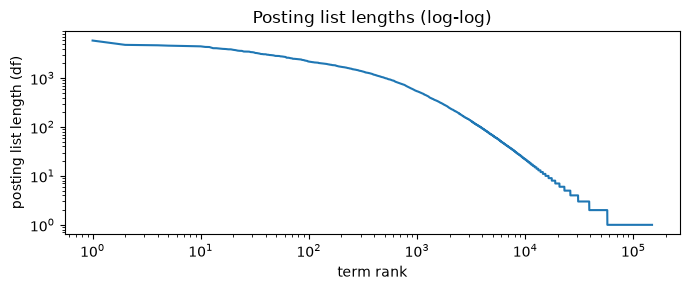

In [2]:
t0 = time.perf_counter()
method = BooleanSearch().fit(corpus)                    # tokenize() every repository once, fill the index
build_s = time.perf_counter() - t0
idx = method.index

print(f"built in {build_s:.1f} s | {idx.n_docs:,} repositories | {len(idx):,} distinct terms")
print(f"tokens per repository: median {np.median(idx.doc_len):.0f}, max {max(idx.doc_len):,}")
for w in ["inventory", "nestjs", "postgresql", "react", "laravel", "flutter", "firebase", "spring", "pos"]:
    t = tokenize(w)[0]                                   # the shared tokenizer turns "pos" into "po"
    print(f"  {w:12s} -> {t:11s} in {idx.df(t):5,} repositories")

# how skewed are the posting lists? (a few huge lists, a very long tail of tiny ones)
df = pd.Series({t: idx.df(t) for t in idx.index}).sort_values(ascending=False)
print(f"terms in 1 repository only: {(df == 1).sum():,} ({(df == 1).mean():.0%}) | top 10:", ", ".join(df.index[:10]))
fig, ax = plt.subplots(figsize=(7, 3))
ax.loglog(np.arange(1, len(df) + 1), df.values)
ax.set_xlabel("term rank"); ax.set_ylabel("posting list length (df)"); ax.set_title("Posting list lengths (log-log)")
plt.tight_layout(); plt.show()

## 3. Search: a free-text query in, a ranked list out

A small parser for AND, OR, NOT and brackets. Each word is looked up in the index; the operators are set operations on the posting lists.

**Check:** the top 10 for `DEV[0]` look plausible when you read their names and descriptions.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
import re

def boolean(query: str) -> set[int]:
    """'inventory AND (nestjs OR express) AND NOT tutorial'. NOT binds tightest, then AND, then OR.
    Two words next to each other mean AND."""
    toks = re.findall(r"\(|\)|\bAND\b|\bOR\b|\bNOT\b|[^\s()]+", query)
    def expr():
        r = term()
        while toks and toks[0] == "OR":
            toks.pop(0); r = r | term()
        return r
    def term():
        r = factor()
        while toks and toks[0] not in ("OR", ")"):
            if toks[0] == "AND": toks.pop(0)
            r = r & factor()
        return r
    def factor():
        t = toks.pop(0)
        if t == "NOT": return ALL - factor()
        if t == "(":
            r = expr(); toks.pop(0); return r            # drop the ")"
        words = tokenize(t)
        return set.intersection(*(postings.get(w, set()) for w in words)) if words else ALL
    return expr()

print(len(boolean("inventory AND nestjs")), len(boolean("inventory AND (nestjs OR express)")))
```
</details>

In [3]:
# The Boolean query language (method.boolean): NOT > AND > OR, brackets, "phrases", two words = AND
for q in ["inventory", "nestjs", "inventory AND nestjs", "inventory AND (nestjs OR express)",
          "inventory AND nestjs AND NOT tutorial", '"point of sale"', "point sale"]:
    print(f"{len(method.boolean(q)):5,}  {q}")

# Free text (method.search): AND of the words, OR if AND finds nothing, ordered by words matched
print(f"\n# {DEV[0]}   tokens: {tokenize(DEV[0])}")
rows = corpus.set_index("full_name")
for h in method.search(DEV[0], 10):
    r = rows.loc[h["doc_id"]]
    print(f"{h['score']:3.0f}  {h['doc_id'][:44]:44s} ★{r.stars:<6} {str(r.description)[:60]}")

1,093  inventory
  450  nestjs
   56  inventory AND nestjs
  211  inventory AND (nestjs OR express)
   54  inventory AND nestjs AND NOT tutorial
  389  "point of sale"
  556  point sale

# beginner inventory management system nestjs postgresql   tokens: ['beginner', 'inventory', 'management', 'system', 'nestjs', 'postgresql']
  6  aminesaadGU/aqua-log                         ★5      not specified
  6  atryx/backend-developer-roadmap-2026         ★25     Backend developer roadmap for 2026 — languages, frameworks, 


## 4. Move it into `src/discovery/index/boolean.py` as `BooleanSearch`

The stub is already there with the right signature. Fill in `fit` and `search` (and `params`), then load it here with `discovery.index.boolean.BooleanSearch`: autoreload picks up your edits.

**Check:** `check_hits` passes below, and in a terminal `pytest tests/test_methods.py -k boolean` passes (it was skipped until now).

<details><summary>The search method, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
    def search(self, query, k=10):
        terms = tokenize(query)
        hits = set.intersection(*(self.postings.get(t, set()) for t in terms)) if terms else set()
        if not hits:                                      # AND found nothing: fall back to OR
            hits = set().union(*(self.postings.get(t, set()) for t in terms))
        score = {i: sum(i in self.postings.get(t, ()) for t in terms) for i in hits}
        best = sorted(hits, key=lambda i: (-score[i], i))[:k]
        return [{"doc_id": self.ids[i], "score": float(score[i])} for i in best]
```
</details>

In [4]:
method = BooleanSearch().fit(corpus)
check_hits(method.search(DEV[0], 10), k=10)
import subprocess, sys
print(subprocess.run([sys.executable, "-m", "pytest", "-q", "../tests/test_boolean.py", "../tests/test_methods.py", "-k", "boolean", "--color=no", "-p", "no:cacheprovider"],
                     capture_output=True, text=True).stdout[-300:])
method.params()

....................                                                     [100%]
20 passed, 8 deselected in 4.48s



{'operator': 'AND, then OR',
 'fields': ['name', 'description', 'topics', 'readme']}

## 5. Test exact matching: the set rules must hold

Boolean retrieval is exact, so it can be checked exactly. These identities hold for any two words; if one fails, the parser or the index is wrong.

**Check:** All asserts pass, and the 5 repositories you opened really contain both words (search the README on GitHub with Ctrl+F).

<details><summary>The check, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
A, B = boolean("inventory"), boolean("nestjs")
assert boolean("inventory AND nestjs") == A & B
assert len(boolean("inventory OR nestjs")) == len(A) + len(B) - len(A & B)
assert len(boolean("NOT inventory")) + len(A) == len(ids)
assert boolean("inventory nestjs") == boolean("inventory AND nestjs")      # implicit AND
assert boolean("NOT inventory AND nestjs") == (ALL - A) & B                # NOT binds tighter than AND
# open 5 hits of "inventory AND nestjs" on GitHub: does each really contain both words?
print(corpus.loc[sorted(A & B)[:5], ["full_name", "description"]])
```
</details>

In [5]:
boolean, ALL = method.boolean, set(range(len(ids)))
for a, b in [("inventory", "nestjs"), ("react", "express"), ("school", "laravel"), ("chat", "firebase")]:
    A, B = boolean(a), boolean(b)
    assert boolean(f"{a} AND {b}") == A & B
    assert len(boolean(f"{a} OR {b}")) == len(A) + len(B) - len(A & B)
    assert len(boolean(f"NOT {a}")) + len(A) == len(ids)
    assert boolean(f"{a} {b}") == boolean(f"{a} AND {b}")          # implicit AND
    assert boolean(f"NOT {a} AND {b}") == (ALL - A) & B            # NOT binds tighter than AND
    assert boolean(f"NOT ({a} OR {b})") == ALL - (A | B)           # De Morgan
    print(f"ok  {a:10s} {len(A):5,} | {b:10s} {len(B):5,} | AND {len(A & B):4,} | OR {len(A | B):5,}")

# Independent check: does every hit of "inventory AND nestjs" really contain both words?
A, B = boolean("inventory"), boolean("nestjs")
both = sorted(A & B)
assert all({"inventory", "nestjs"} <= set(tokenize(text[i])) for i in both)
print(f"\nall {len(both)} hits of 'inventory AND nestjs' contain both tokens")
print(corpus.loc[both[:5], ["full_name", "description"]].to_string())

ok  inventory  1,093 | nestjs       450 | AND   56 | OR 1,487
ok  react      2,908 | express    1,176 | AND  693 | OR 3,391
ok  school       543 | laravel      944 | AND  131 | OR 1,356
ok  chat       1,818 | firebase     608 | AND  265 | OR 2,161

all 56 hits of 'inventory AND nestjs' contain both tokens
                              full_name                                                                                                                                                          description
682                 DavidRiusB/ChilyAPI                        This API handles operations related to an e-commerce platform, including user authentication, product management, order processing, and more.
714       DevVictor19/ecommerce-backend                                                                                                                                      Backend for a generic ecommerce
774              DonPharoah/ever-demand                                       

## 6. Read your top 10 on the development queries

Read them. Write down two good results and two bad ones, and why each bad one ranked high (in the markdown cell under the output).

**Check:** you can say in one sentence why each bad result ranked high.

In [6]:
show_top(method, corpus, DEV)


# beginner inventory management system nestjs postgresql   (2 hits)
    6.000  aminesaadGU/aqua-log                         ★5      not specified
    6.000  atryx/backend-developer-roadmap-2026         ★25     Backend developer roadmap for 2026 — languages, frameworks, 

# point of sale app with react   (10 hits)
    4.000  6xpencer/InventoryPOS-PHP-MYSQL--fully-funct ★5      not specified
    4.000  Aaiyub-shaikh/odoo-cafe-pos                  ★12     not specified
    4.000  Afrasiab006/Afrasiab006                      ★21     Hello world this is my profile
    4.000  Agilo/medusa-pos-starter                     ★122    not specified
    4.000  Andersonlimahw/lemon-ai-hub                  ★18     My ai marketplace with skills, agents an more
    4.000  BB-AI-Arena/helix-ai-virtual-receptionist    ★7      Helix AI Virtual Receptionist: self-hosted multilingual AI p
    4.000  Bey-Wallet/BeyWallet                         ★20     Modular, Local-First Cashu & Nostr Wallet. Direct Bitcoi

*Two good results, two bad results, and why:*

- **Good:** `4jean/lav_sms` (★1190, "Laravel School Management System") for *school management system laravel*: all 4 words in the name and description, a real, popular project.
- **Good:** `Fetulhak/Spring-Boot-Hotel-Booking-APP-Backend` for *hotel booking system spring boot*: exactly what was asked, and every word appears in the name.
- **Bad:** `Ileriayo/markdown-badges` (★17k) for *simple chat application flutter firebase*: a list of README badges. Its 14k-character README names almost every technology, so it contains all 5 words. Boolean can't tell "mentions" from "is about".
- **Bad:** `atryx/backend-developer-roadmap-2026` for the inventory/NestJS query: a learning roadmap that lists NestJS, PostgreSQL, "system", "management", … Same cause: long lists (roadmaps, awesome-lists, profile READMEs such as `Afrasiab006/Afrasiab006`) match everything, and with ties broken by corpus order they float to the top alphabetically.


## 7. Tune on the 5 development queries only

There is little to tune. Compare AND-only vs AND-then-OR on the development queries: how many queries return nothing with AND only?

Until Phase 13 gives the development labels, compare settings by reading the top 10 (step 6). When `eval/qrels.csv` has the development labels, use `discovery.evaluation.metrics.ndcg_at_k` and keep the setting with the best mean NDCG@10. **Never tune on the 20 test queries.**

**Check:** a small table: each setting tried, what changed in the top 10 (later: mean NDCG@10). Keep the best and note it in the sheet.

In [7]:
from discovery.index.boolean import BooleanSearch, FIELDS

settings = {"AND only": BooleanSearch(operator="and"), "AND, then OR": BooleanSearch(operator="and_or"),
            "OR only": BooleanSearch(operator="or"),
            "AND, then OR · name+description+topics": BooleanSearch(operator="and_or", fields=("name", "description", "topics"))}
for s in settings.values():
    s.fit(corpus)

def n_and(m, q):           # size of the full AND set for a query
    terms = list(dict.fromkeys(tokenize(q)))
    return len(frozenset.intersection(*(m.index.rows(t) for t in terms)))

table = pd.DataFrame({name: [len(m.search(q, 10)) for q in DEV] for name, m in settings.items()}, index=DEV)
table.insert(0, "AND matches (all)", [n_and(method, q) for q in DEV])
print("hits returned in the top 10 per development query:")
display(table)
print("queries with nothing from AND only:", int((table["AND only"] == 0).sum()), "of", len(DEV))

# Without labels yet: how different are the top 10s? (Jaccard overlap with the chosen setting)
base = settings["AND, then OR"]
for name, m in settings.items():
    ov = []
    for q in DEV:
        a, b = {h["doc_id"] for h in m.search(q)}, {h["doc_id"] for h in base.search(q)}
        ov.append(len(a & b) / len(a | b) if a | b else 1.0)          # Jaccard
    print(f"{name:42s} top-10 Jaccard with AND-then-OR: {np.mean(ov):.2f}  per query: {[round(x, 2) for x in ov]}")

# OR ranked by words matched puts every AND match first (score = all words), then fills the top 10:
q = DEV[0]
print(f"\n# {q}: AND-then-OR returns {len(base.search(q))} hits; OR-ranked top 10:")
for h in settings["OR only"].search(q, 10):
    print(f"  {h['score']:.0f}/{len(set(tokenize(q)))}  {h['doc_id']}")

hits returned in the top 10 per development query:


,AND matches (all),AND only,"AND, then OR",OR only,"AND, then OR · name+description+topics"
beginner inventory management system nestjs postgresql,2,2,2,10,10
point of sale app with react,163,10,10,10,5
school management system laravel,103,10,10,10,10
hotel booking system spring boot,14,10,10,10,2
simple chat application flutter firebase,62,10,10,10,2


queries with nothing from AND only: 0 of 5
AND only                                   top-10 Jaccard with AND-then-OR: 1.00  per query: [1.0, 1.0, 1.0, 1.0, 1.0]
AND, then OR                               top-10 Jaccard with AND-then-OR: 1.00  per query: [1.0, 1.0, 1.0, 1.0, 1.0]
OR only                                    top-10 Jaccard with AND-then-OR: 0.84  per query: [0.2, 1.0, 1.0, 1.0, 1.0]
AND, then OR · name+description+topics     top-10 Jaccard with AND-then-OR: 0.11  per query: [0.0, 0.0, 0.33, 0.2, 0.0]

# beginner inventory management system nestjs postgresql: AND-then-OR returns 2 hits; OR-ranked top 10:
  6/6  aminesaadGU/aqua-log
  6/6  atryx/backend-developer-roadmap-2026
  5/6  DavidRiusB/ChilyAPI
  5/6  DivaQueen-dev/free-cs-roadmap
  5/6  Hancie123/Hancie123
  5/6  HenestrosaDev/sololearn
  5/6  Hordekiller/Atlas-Shop
  5/6  Integerous/goQuality-dev-contents
  5/6  Malte2036/thw-tools
  5/6  Raktim94/nodedr-restaurant-pos


**Settings tried (no labels yet, so judged by hit counts and reading the top 10):**

| Setting | Empty results (of 5) | Top 10 vs AND-then-OR (Jaccard) | Verdict |
|---|---|---|---|
| AND only | 0 | 1.00 | Same top 10 here, but returns only 2 hits for the long inventory query |
| **AND, then OR** (kept, the agreed default) | 0 | 1.00 | Never empty; the fallback never fired on these 5 queries |
| OR, ranked by words matched | 0 | 0.84 | Gives the same AND matches first (6/6), then fills up to 10 with 5/6 matches. Better for top-10 metrics: re-check with NDCG@10 once Phase 13 labels arrive |
| AND, then OR · name + description + topics only | 0 | 0.11 | Drops the README: far fewer list/profile hits, but only 2 hits for 2 of the queries. Worth testing with labels |

Result: no development query returns nothing with AND only (0 of 5). The real weakness is the opposite: a long query (6 words) leaves only 2 AND matches, and AND-then-OR stops there.


## 8. Speed, results file, hand in

`measure()` times the build and the queries; `save_results()` writes `eval/results/boolean.json` in the format the Results sheet imports. The metrics stay empty until Phase 13–14: then Member 6's `evaluate_method(method, split="test")` fills them in and you import the file in the **Results sheet** tab of the team plan, add your observations and download the PDF.

**Check:** `eval/results/boolean.json` exists; this notebook is committed with its outputs on `dev-boolean`; `pytest` passes.

In [8]:
speed = measure(lambda: BooleanSearch().fit(corpus), DEV)
print(speed)
save_results(method, speed)

{'build_s': 18.2, 'query_ms_median': 0.24, 'index_mb': 33.8}


PosixPath('/home/urjazz/Desktop/Y4_Project/Open-Source-Project-Discovery/backend/eval/results/boolean.json')

## Extra (optional): Phrase queries with a positional index

Store word positions as well (`term → {row: [positions]}`) and support `"point of sale"` as a phrase: the words must appear next to each other. Compare precision@10 on queries that contain a phrase.

In [9]:
# Phrase queries via the positional index: "point of sale" must appear as consecutive tokens
# (stop words are removed before positions are counted, so "point of sale" == "point sale" adjacent)
rows = corpus.set_index("full_name")
for q in ["point sale", '"point of sale"', "school management", '"school management"', "hotel booking", '"hotel booking"',
          "real time chat", '"real time chat"']:
    hits = method.boolean(q)
    print(f"{len(hits):5,}  {q}")

hits = sorted(method.boolean('"point of sale"'))
loose = sorted(method.boolean("point sale") - set(hits))
print("\nphrase hits (first 5):"); print(corpus.loc[hits[:5], ["full_name", "description"]].to_string())
print("\nboth words but NOT as a phrase (first 5):"); print(corpus.loc[loose[:5], ["full_name", "description"]].to_string())

  556  point sale
  389  "point of sale"
  454  school management
  313  "school management"
  108  hotel booking
   46  "hotel booking"
1,127  real time chat
  248  "real time chat"

phrase hits (first 5):
                                            full_name                               description
10                 0xairdropfarmer/simple-pos-in-node  build simple pos in node.js and react.js
14                                    101Loop/Cafe-BE         Mini Point of Sale backend system
25                           2qx/awesome-bitcoin-cash        Bitcoin Cash projects & resources 
39  6xpencer/InventoryPOS-PHP-MYSQL--fully-functional                             not specified
68                        Aaiyub-shaikh/odoo-cafe-pos                             not specified

both words but NOT as a phrase (first 5):
                                    full_name                                                                                                                                 

## What we found

- **Index:** 8,223 repositories, 148,623 distinct terms, 61% of them in a single repository (typos, ids, URLs). Median 361 tokens per repository. Build ≈ 16–18 s (almost all of it is `tokenize()`), median query **0.24 ms**, pickled size **33.8 MB**.
- **Exact matching holds:** all set identities (AND = ∩, OR by inclusion-exclusion, NOT = complement, implicit AND, NOT before AND, De Morgan) pass on the real corpus for 4 word pairs, and all 56 hits of `inventory AND nestjs` really contain both tokens. 20 unit tests pass, including the shared contract tests.
- **Best setting:** kept *AND, then OR* (the agreed default). *OR ranked by words matched* is a candidate to re-check with labels: it is identical when AND finds ≥ 10 and fills the list when it doesn't (DEV[0]: 2 → 10 hits).
- **Good:** short, specific queries whose words appear in the name (Laravel school systems, Spring Boot hotel booking, Flutter/Firebase chat apps).
- **Bad:** long READMEs that list everything (awesome-lists, roadmaps, badge collections, profile READMEs) match every query; with no score, ties are in corpus order, which is alphabetical by owner. This is exactly what TF-IDF/BM25 length normalisation and IDF should fix: the floor to beat.
- **Surprising, for Member 6:** the shared `tokenize()` lemmatises some technology acronyms: `pos → po`, `cms → cm`, `sms → sm`, `ios → io`. Matching still works because queries go through the same function, but `po`/`io` can collide with other words. Suggest adding them to the keep list (`technologies.yaml`) on `main`.
- **Extra (phrases):** the positional index answers `"point of sale"` (389 repositories vs 556 with both words anywhere), `"hotel booking"` 46 vs 108, `"real time chat"` 248 vs 1,127. Phrases remove many accidental matches. Precision@10 comparison waits for the Phase 13 labels.
- **Still to do after Phase 13–14:** NDCG@10 for the settings above, `evaluate_method(method, split="test")` to fill the metrics in `eval/results/boolean.json`, then the Results sheet PDF.
